# 📊 Analysis of Book1.csv
A simple data analysis notebook covering:
- Data loading & inspection
- Missing value detection & handling
- Descriptive statistics
- Basic visualizations

## 1. Import Libraries

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

print('Libraries loaded successfully ✅')

Libraries loaded successfully ✅


## 2. Load the Data

In [4]:
df = pd.read_csv('Book1.csv')

# Drop fully empty rows (like the blank trailing row)
df.dropna(how='all', inplace=True)

print(f'Dataset shape: {df.shape[0]} rows × {df.shape[1]} columns')
df

Dataset shape: 8 rows × 6 columns


,R_ID,F_Name,L_Name,No_Books,No_papers,R_Score
0,1001.0,Harsh,Bhasin,9.0,25.0,15.37
1,1002.0,Kumar,Gaurav,NaN,10.0,10.23
2,1003.0,Lovish,Kundu,NaN,8.0,8.20
3,NaN,Arush,Jasuja,2.0,NaN,12.56
4,1005.0,Kim,Parsons,NaN,15.0,NaN
5,1006.0,Pulin,Verma,NaN,2.0,4.00
6,1007.0,ABC,XYZ,5.0,8.0,7.21
7,1008.0,LMN,QRS,1.0,13.0,9.76


## 3. Basic Info & Data Types

In [5]:
print('--- Data Types ---')
print(df.dtypes)
print()
print('--- Column Names ---')
print(df.columns.tolist())

--- Data Types ---
R_ID         float64
F_Name           str
L_Name           str
No_Books     float64
No_papers    float64
R_Score      float64
dtype: object

--- Column Names ---
['R_ID', 'F_Name', 'L_Name', 'No_Books', 'No_papers', 'R_Score']


## 4. Missing Value Analysis

=== Missing Values Summary ===
           Missing Count  Missing %
R_ID                   1       12.5
F_Name                 0        0.0
L_Name                 0        0.0
No_Books               4       50.0
No_papers              1       12.5
R_Score                1       12.5


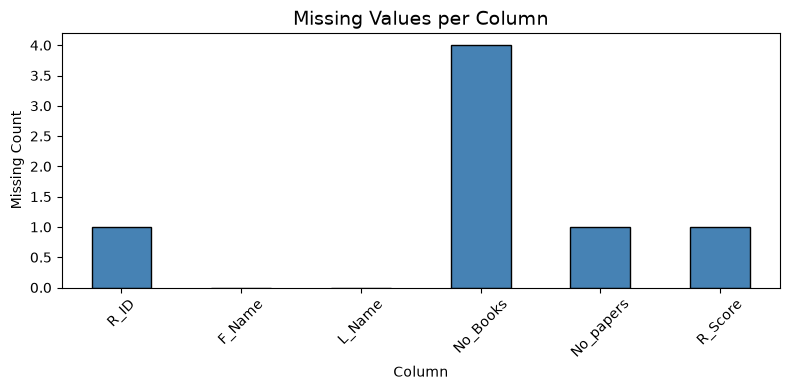

In [6]:
missing = df.isnull().sum()
missing_pct = (df.isnull().sum() / len(df) * 100).round(2)

missing_df = pd.DataFrame({
    'Missing Count': missing,
    'Missing %': missing_pct
})

print('=== Missing Values Summary ===')
print(missing_df)

# Visualise missing values
fig, ax = plt.subplots(figsize=(8, 4))
missing_df['Missing Count'].plot(kind='bar', ax=ax, color='steelblue', edgecolor='black')
ax.set_title('Missing Values per Column', fontsize=14)
ax.set_xlabel('Column')
ax.set_ylabel('Missing Count')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## 5. Descriptive Statistics (Numeric Columns)

In [7]:
df.describe().round(2)

,R_ID,No_Books,No_papers,R_Score
count,7.00,4.00,7.00,7.00
mean,1004.57,4.25,11.57,9.62
std,2.64,3.59,7.23,3.69
min,1001.00,1.00,2.00,4.00
25%,1002.50,1.75,8.00,7.70
50%,1005.00,3.50,10.00,9.76
75%,1006.50,6.00,14.00,11.40
max,1008.00,9.00,25.00,15.37


## 6. Fill Missing Values

In [8]:
df_clean = df.copy()

# Fill missing R_ID with forward-fill (pandas 2.0+ compatible)
df_clean['R_ID'] = df_clean['R_ID'].ffill().astype(int)

# Fill numeric columns with their column mean
for col in ['No_Books', 'No_papers', 'R_Score']:
    col_mean = df_clean[col].mean()
    df_clean[col] = df_clean[col].fillna(round(col_mean, 2))

print('Missing values after cleaning:')
print(df_clean.isnull().sum())
print()
df_clean


Missing values after cleaning:
R_ID         0
F_Name       0
L_Name       0
No_Books     0
No_papers    0
R_Score      0
dtype: int64



,R_ID,F_Name,L_Name,No_Books,No_papers,R_Score
0,1001,Harsh,Bhasin,9.00,25.00,15.37
1,1002,Kumar,Gaurav,4.25,10.00,10.23
2,1003,Lovish,Kundu,4.25,8.00,8.20
3,1003,Arush,Jasuja,2.00,11.57,12.56
4,1005,Kim,Parsons,4.25,15.00,9.62
5,1006,Pulin,Verma,4.25,2.00,4.00
6,1007,ABC,XYZ,5.00,8.00,7.21
7,1008,LMN,QRS,1.00,13.00,9.76


## 7. Distribution of R_Score

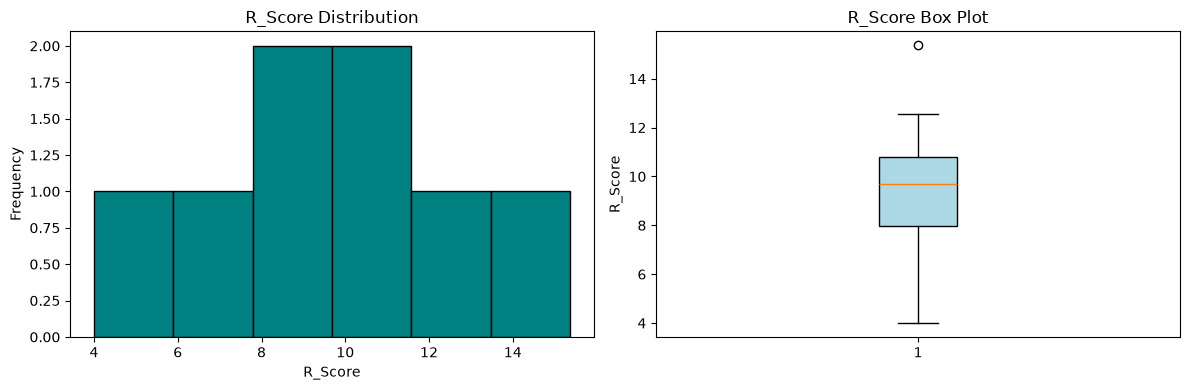

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Histogram
axes[0].hist(df_clean['R_Score'], bins=6, color='teal', edgecolor='black')
axes[0].set_title('R_Score Distribution')
axes[0].set_xlabel('R_Score')
axes[0].set_ylabel('Frequency')

# Box plot
axes[1].boxplot(df_clean['R_Score'], patch_artist=True,
                boxprops=dict(facecolor='lightblue'))
axes[1].set_title('R_Score Box Plot')
axes[1].set_ylabel('R_Score')

plt.tight_layout()
plt.show()

## 8. Comparing No_Books vs No_papers per Reader

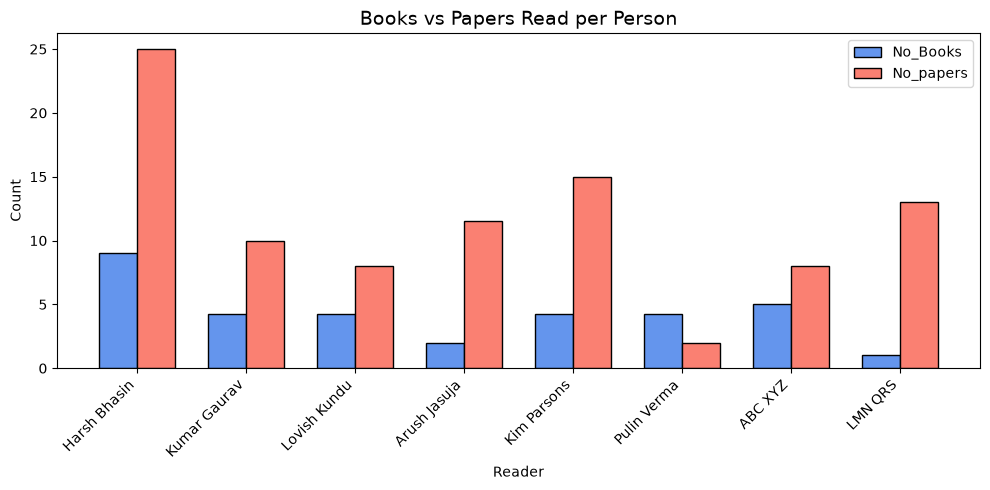

In [10]:
labels = df_clean['F_Name'] + ' ' + df_clean['L_Name']
x = np.arange(len(labels))
width = 0.35

fig, ax = plt.subplots(figsize=(10, 5))
ax.bar(x - width/2, df_clean['No_Books'],  width, label='No_Books',  color='cornflowerblue', edgecolor='black')
ax.bar(x + width/2, df_clean['No_papers'], width, label='No_papers', color='salmon',         edgecolor='black')

ax.set_title('Books vs Papers Read per Person', fontsize=14)
ax.set_xlabel('Reader')
ax.set_ylabel('Count')
ax.set_xticks(x)
ax.set_xticklabels(labels, rotation=45, ha='right')
ax.legend()
plt.tight_layout()
plt.show()

## 9. Correlation Analysis

=== Correlation Matrix ===
           No_Books  No_papers  R_Score
No_Books       1.00       0.51     0.33
No_papers      0.51       1.00     0.90
R_Score        0.33       0.90     1.00


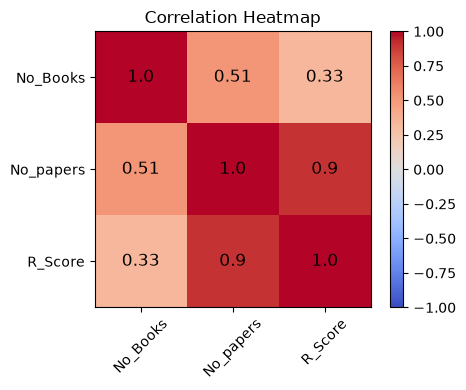

In [11]:
numeric_cols = df_clean[['No_Books', 'No_papers', 'R_Score']]
corr = numeric_cols.corr().round(2)

print('=== Correlation Matrix ===')
print(corr)

fig, ax = plt.subplots(figsize=(5, 4))
im = ax.imshow(corr, cmap='coolwarm', vmin=-1, vmax=1)
plt.colorbar(im, ax=ax)
ax.set_xticks(range(len(corr.columns)))
ax.set_yticks(range(len(corr.columns)))
ax.set_xticklabels(corr.columns, rotation=45)
ax.set_yticklabels(corr.columns)
ax.set_title('Correlation Heatmap')

# Annotate cells
for i in range(len(corr)):
    for j in range(len(corr.columns)):
        ax.text(j, i, corr.iloc[i, j], ha='center', va='center', color='black', fontsize=12)

plt.tight_layout()
plt.show()

## 10. Summary

| Metric | Value |
|--------|-------|
| Total Records | 8 |
| Columns | R_ID, F_Name, L_Name, No_Books, No_papers, R_Score |
| Missing Values | R_ID(1), No_Books(5), No_papers(1), R_Score(1) |
| Avg R_Score | ~9.67 |
| Max R_Score | 15.37 (Harsh Bhasin) |
| Min R_Score | 4.0 (Pulin Verma) |